 # Exploratory Data Analysis of Holistic Health and Lifestyle

## Purpose

The purpose of this exploratory data analysis (EDA) is to investigate how lifestyle factors relate to the overall health score in the Holistic Health and Lifestyle dataset. Using Python, this notebook will explore the dataset, examine patterns and relationships, and produce visualisations and findings to support the team's interactive dashboard. The analysis will also consider the limitations of the synthetic dataset and the formula used to calculate the overall health score.


## Objectives

* Explore the cleaned Holistic Health and Lifestyle dataset to understand its structure, variables and characteristics.
* Use descriptive statistics and visualisations to investigate patterns and distributions in lifestyle factors and the overall health score.
* Examine relationships between lifestyle factors and the overall health score, considering the direction and strength of observed associations.
* Compare lifestyle measures across the Poor, Average and Good health-status groups to identify differences and patterns.
* Interpret and document the key findings for the team's interactive dashboard, recognising that the dataset is synthetic and the overall health score is calculated using a predefined formula.
* Summarise the main findings, acknowledge the limitations of the analysis, and identify areas for further investigation.


## Inputs

- The cleaned holistic health and lifestyle dataset provided by the team.
- The data dictionary or dataset documentation, if available, to understand the meaning of the variables.
- Python libraries required for data analysis and visualisation.


## Outputs

- Exploratory summaries describing the dataset and its variables.
- Visualisations illustrating relevant patterns and relationships.
- Written interpretations of the visualisations and statistical findings.
- A summary of key findings, limitations and recommendations for further analysis.

## Additional Comments

- This notebook focuses on exploratory data analysis, visualisation and interpretation.
- Data preparation and cleaning are covered in the team's preceding notebook.
- Findings will be interpreted carefully because observed relationships do not necessarily demonstrate cause and effect.
- Conclusions will reflect the dataset's limitations and should not be interpreted as medical advice.


---

# Section 1: Load and Inspect the Dataset

This section loads the cleaned Holistic Health and Lifestyle dataset into Python using the pandas library. The initial inspection will help us understand the dataset's dimensions, column names and data types before beginning the exploratory data analysis.

The dataset has already been cleaned and validated in the team's preceding notebook. Therefore, this section focuses on loading the prepared data and understanding its structure rather than repeating the cleaning process.


### 1.1 Load the Cleaned Dataset

The pandas library will be used to load the cleaned CSV file into a DataFrame. A DataFrame allows us to organise, inspect and analyse the dataset using Python.

The dataset will be loaded from the `cleaned_datasets` folder in the project directory.


In [1]:
# Import pandas for data analysis
import pandas as pd

# Load the cleaned dataset from the project folder
df = pd.read_csv(
    "../cleaned_datasets/holistic_health_lifestyle_cleaned.csv"
)

# Confirm that the dataset loaded successfully
print("Cleaned dataset loaded successfully.")

Cleaned dataset loaded successfully.


In [2]:
 # Find the cleaned dataset within the project folder
from pathlib import Path

project_folder = Path.cwd().parent
dataset_file = project_folder / "cleaned_datasets" / "holistic_health_lifestyle_cleaned.csv"

print("Dataset file exists:", dataset_file.exists())
print("Dataset path:", dataset_file)

Dataset file exists: True
Dataset path: c:\Users\kavit\OneDrive\Desktop\Hackathon\Holistic-Health-and-Lifestyle-Score-Dataset\cleaned_datasets\holistic_health_lifestyle_cleaned.csv


### 1.2 Inspect the Dataset Dimensions and Columns

After loading the dataset, we will examine its dimensions and column names. This will help us understand how many records and variables are available for analysis and confirm which lifestyle measures and health outcomes are included.


In [3]:
# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset dimensions: (10000, 11)

Column names:
['Physical_Activity', 'Nutrition_Score', 'Stress_Level', 'Mindfulness', 'Sleep_Hours', 'Hydration', 'BMI', 'Alcohol', 'Smoking', 'Overall_Health_Score', 'Health_Status']


**Explanation**

The `df.shape` attribute returns the number of rows and columns in the DataFrame. The `df.columns.tolist()` method displays all column names as a Python list.

The dataset contains lifestyle measures, including physical activity, nutrition, stress, mindfulness, sleep, hydration, BMI, alcohol consumption and smoking. It also contains the overall health score and the associated health-status category.


**Finding**

* The dataset contains **10,000 rows and 11 columns**.
* Nine columns represent lifestyle measures.
* `Overall_Health_Score` represents the calculated overall health score.
* `Health_Status` categorises records into Poor, Average or Good groups.
* The dataset provides variables for exploring lifestyle patterns and their relationships with the calculated health score.


### 1.3 Inspect the First Five Records

The first five records will help us understand how the dataset is organised and what the values in each column look like. This initial inspection will help us prepare for the descriptive statistical analysis.


In [4]:
# Display the first five records of the dataset
df.head()

,Physical_Activity,Nutrition_Score,Stress_Level,Mindfulness,Sleep_Hours,Hydration,BMI,Alcohol,Smoking,Overall_Health_Score,Health_Status
0,54.934283,5.643011,5.696572,0.000000,6.292214,2.578565,24.275932,4.280610,8.984006,36.950187,Poor
1,42.234714,6.389001,5.566647,4.450144,8.519054,2.448713,25.970141,7.461846,3.223304,55.167774,Average
2,57.953771,5.805238,3.126960,9.129716,6.702720,3.261433,25.193857,0.000000,4.600482,78.304426,Good
3,75.460597,7.220836,6.159168,16.496689,7.135854,3.726265,19.527300,9.958423,3.947706,94.018274,Good
4,40.316933,9.394357,2.019835,25.241623,8.076086,3.049478,23.348229,4.320347,8.084322,100.000000,Good


**Explanation**

The `df.head()` method displays the first five rows of the DataFrame by default. It allows us to inspect the structure of the records and see examples of the values stored in each variable.


### 1.4 Inspect Data Types

In this step, we will examine the data type of each column. Understanding data types helps us determine how each variable is stored in Python and which statistical methods and visualisations are suitable for our analysis.


In [5]:
# Display the data type of each column
df.dtypes

Physical_Activity       float64
Nutrition_Score         float64
Stress_Level            float64
Mindfulness             float64
Sleep_Hours             float64
Hydration               float64
BMI                     float64
Alcohol                 float64
Smoking                 float64
Overall_Health_Score    float64
Health_Status            object
dtype: object

**Explanation**

The `df.dtypes` attribute displays the data type of each column in the DataFrame. Numeric data types can be used for calculations and statistical analysis, while object data types commonly represent text or categories.


**Finding**

* The dataset contains 11 columns: 10 numeric columns with the `float64` data type and one categorical column, `Health_Status`, with the `object` data type.
* The numeric columns can be used for descriptive statistics and numerical analysis.
* The `Health_Status` column contains the categories Poor, Average and Good, allowing us to compare lifestyle measures across health-status groups.
* The data types are suitable for the planned exploratory data analysis.



#### 1.5 Verify Health Score and Status Data Types

The overall health score and health-status category will be important variables in this analysis. This additional check confirms how these two variables are stored and displays examples of the health-status categories.


In [6]:
# Display the data types of the health score and status columns
print(df[["Overall_Health_Score", "Health_Status"]].dtypes)

# Display example values from the health-status column
print("\nHealth-status examples:")
print(df["Health_Status"].head())

Overall_Health_Score    float64
Health_Status            object
dtype: object

Health-status examples:
0       Poor
1    Average
2       Good
3       Good
4       Good
Name: Health_Status, dtype: object


**Explanation**

The `Overall_Health_Score` column uses the `float64` data type, which supports numerical calculations. The `Health_Status` column uses the `object` data type and contains category labels such as Poor, Average and Good. These variables can therefore be used for numerical analysis and comparisons between health-status groups.


**Finding**

* `Overall_Health_Score` is stored as a numeric variable.
* `Health_Status` contains the categories Poor, Average and Good.
* These variables allow us to examine the overall health score numerically and compare lifestyle measures across the health-status groups.


### 1.6 Check for Missing Values

Although the dataset has already been cleaned and validated, a brief check for missing values will confirm that the data is ready for exploratory analysis. This step verifies data completeness without repeating the cleaning process.


In [7]:
# Count missing values in each column
df.isnull().sum()

Physical_Activity       0
Nutrition_Score         0
Stress_Level            0
Mindfulness             0
Sleep_Hours             0
Hydration               0
BMI                     0
Alcohol                 0
Smoking                 0
Overall_Health_Score    0
Health_Status           0
dtype: int64

**Explanation**

The `df.isnull().sum()` method counts the missing values in each column of the dataset. A value of zero indicates that the corresponding column contains no missing values.

This check confirms that all 11 columns have complete data, consistent with the cleaning and validation carried out in the team's preceding notebook.


**Finding**

* All 11 columns contain **zero missing values**.
* All 10,000 records have values in every column.
* No additional missing-value treatment is required for this analysis.


---

# Section 2: Descriptive Statistical Analysis

This section uses descriptive statistics to summarise the numerical variables in the Holistic Health and Lifestyle dataset. The analysis will help us understand the typical values, variation and ranges of the lifestyle measures and overall health score.

Because the dataset is synthetic and the overall health score is calculated using a predefined formula, the results will be interpreted as patterns within this dataset rather than evidence of real-world health outcomes.


### 2.1 Summary Statistics for Numerical Variables

The `describe()` method provides summary statistics for numerical columns, including the count, mean, standard deviation, minimum, quartiles and maximum.

These statistics will help us understand the distribution of the lifestyle measures and overall health score before creating visualisations.


In [8]:
# Generate summary statistics for numerical columns
df.describe()

,Physical_Activity,Nutrition_Score,Stress_Level,Mindfulness,Sleep_Hours,Hydration,BMI,Alcohol,Smoking,Overall_Health_Score
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,45.047069,6.966599,4.987202,15.224636,7.000194,2.503302,24.095086,3.523663,5.706911,78.227945
std,19.832871,1.883295,1.938195,9.454891,1.468580,0.801660,3.356663,3.270784,5.000260,19.697853
min,0.000000,0.000000,1.000000,0.000000,3.000000,0.500000,18.000000,0.000000,0.000000,2.217088
25%,31.548189,5.675978,3.599696,8.053871,6.003898,1.958461,21.653393,0.298894,1.065818,64.627060
50%,44.948100,7.031693,4.988464,14.896178,7.014341,2.506579,24.072122,2.980658,4.954994,81.118118
75%,58.421618,8.387730,6.327795,21.790305,8.025752,3.052666,26.380536,5.706382,8.991626,97.972163
max,120.000000,10.000000,10.000000,52.278333,10.000000,5.000000,36.376168,18.040621,27.978693,100.000000


**Explanation**

The `df.describe()` method summarises the numerical columns using eight statistics:

* **Count:** The number of available values in each column.
* **Mean:** The average value.
* **Standard deviation (`std`):** How much the values vary around the mean.
* **Minimum (`min`) and maximum (`max`):** The lowest and highest observed values.
* **Quartiles (`25%`, `50%` and `75%`):** These show how the values are distributed. The 50% quartile is the median, or middle value.

These statistics provide an overview of the typical values, variation and ranges of the lifestyle measures and overall health score.


**Finding**

* All 10 numerical columns contain **10,000 observations**, consistent with the missing-value check.
* The mean overall health score is approximately **78.23**, while the median is approximately **81.12**.
* The mean physical activity value is approximately **45.05**, and the mean sleep duration is approximately **7.00 hours**.
* The mean nutrition score is approximately **6.97 out of 10**, while the mean stress level is approximately **4.99 out of 10**.
* The mean mindfulness value is approximately **15.22**, and the mean hydration value is approximately **2.50 litres**.
* The mean BMI is approximately **24.10**, while the mean alcohol and smoking values are approximately **3.52** and **5.71**, respectively.
* The overall health score ranges from approximately **2.22 to 100**, showing substantial variation in the calculated scores.
* The maximum overall health score is **100**, consistent with the score being capped at that value. This may limit the differences visible among records with high scores.

**Interpretation note:** These are descriptive results from a synthetic dataset. They describe the dataset's values and should not be interpreted as estimates of the general population's health or as medical guidance.


### 2.2 Distribution of the Overall Health Score

A histogram will be used to examine the distribution of the `Overall_Health_Score` variable. It groups the scores into intervals and shows how many records fall within each interval.

This visualisation will help identify where scores are concentrated and whether many records have scores close to the maximum of 100. As the score is calculated using a predefined formula and capped at 100, the distribution will be interpreted as a feature of the synthetic dataset rather than a measure of real-world health.


**Purpose of the visualisation**

The histogram will help us understand the spread and concentration of the calculated health scores before examining their relationships with individual lifestyle variables.


In [9]:
%matplotlib inline

from pathlib import Path

# Locate the project root
project_root = Path.cwd()
if project_root.name == "jupyter_notebooks":
    project_root = project_root.parent
# Create a folder for saved chart images
visuals_folder = project_root / "visuals"
visuals_folder.mkdir(parents=True, exist_ok=True)


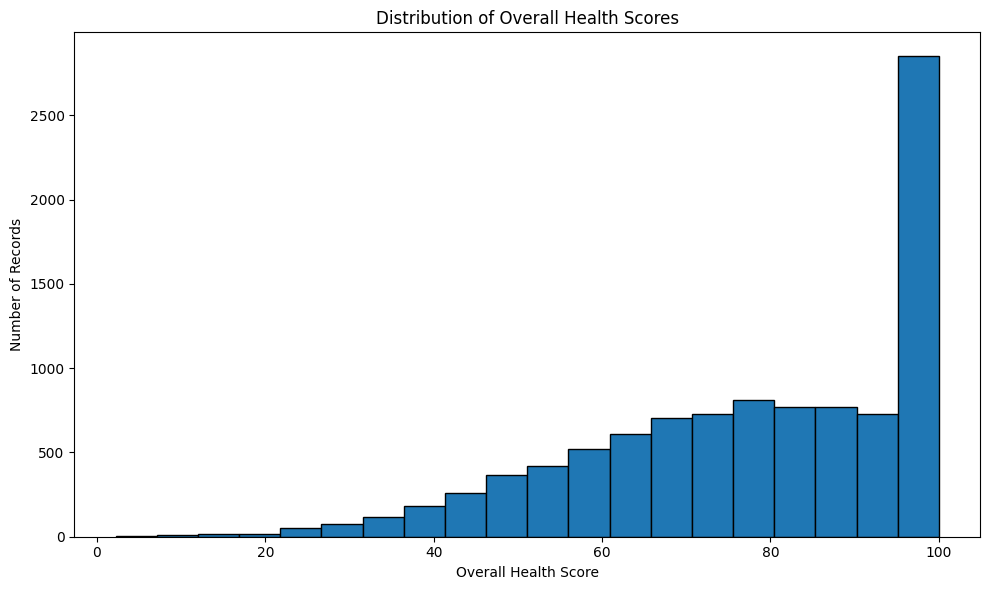

In [10]:
# Import matplotlib for data visualisation
import matplotlib.pyplot as plt

# Create a histogram of the overall health scores
plt.figure(figsize=(10, 6))
plt.hist(df["Overall_Health_Score"], bins=20, edgecolor="black")

# Add a title and axis labels
plt.title("Distribution of Overall Health Scores")
plt.xlabel("Overall Health Score")
plt.ylabel("Number of Records")

# Save and display the histogram
plt.tight_layout()

plt.savefig(
    visuals_folder / "01_overall_health_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



**Explanation**

The histogram shows the distribution of the `Overall_Health_Score` across 10,000 records. Each bar represents the number of records within a particular score interval.

The distribution is negatively skewed (left-skewed), with more records concentrated towards the higher end of the score range and a tail extending towards lower scores. Very few records have scores below 30.

A noticeable increase in the final interval, between approximately 95 and 100, indicates a high concentration of records near the maximum possible score. This pattern is consistent with a ceiling effect because the overall health score is capped at 100.

The distribution describes the scores generated within this synthetic dataset and should not be interpreted as evidence of the health of the general population.


**Finding**

* **Left-skewed distribution:** The scores are concentrated towards the higher end, with relatively few records below 30.
* **Concentration near the maximum:** Approximately 2,851 records (28.5% of the dataset) fall within the final histogram interval, approximately 95–100.
* **Mean and median:** The mean score is approximately 78.23, while the median is approximately 81.12. The higher median is consistent with the observed left-skewed distribution.
* **Potential ceiling effect:** The concentration of scores near 100 may reduce the ability of the score to distinguish between records with different lifestyle measures at the upper end.
* **Limitation:** The overall health score is calculated using a predefined formula and capped at 100. The observed distribution therefore reflects the characteristics of the synthetic dataset and its scoring method, rather than real-world population health.


# Section 3: Correlation Analysis

This section examines the relationships between numerical lifestyle variables and the `Overall_Health_Score`. Correlation analysis will help identify the direction and strength of relationships between variables in the dataset.

The results will be interpreted carefully because the overall health score is calculated using a predefined formula based on lifestyle variables. Consequently, some relationships may reflect how the score was constructed rather than independent evidence of health outcomes.


### 3.1 Calculate the Correlation Matrix

A correlation matrix summarises the strength and direction of relationships between numerical variables. Correlation values range from -1 to +1:

* **Close to +1:** A strong positive relationship; as one variable increases, the other tends to increase.
* **Close to -1:** A strong negative relationship; as one variable increases, the other tends to decrease.
* **Close to 0:** A weak or no linear relationship.

This analysis will focus particularly on the relationships between the lifestyle variables and `Overall_Health_Score`. Because the health score is calculated from the lifestyle variables using a predefined formula, correlations with the score may partly reflect the formula's design. Correlation does not establish causation.


In [11]:
# Calculate correlations between numerical variables
correlation_matrix = df.corr(numeric_only=True)

# Display the correlation matrix
correlation_matrix

,Physical_Activity,Nutrition_Score,Stress_Level,Mindfulness,Sleep_Hours,Hydration,BMI,Alcohol,Smoking,Overall_Health_Score
Physical_Activity,1.000000,-0.008942,0.023377,-0.011513,-0.009958,-0.021959,-0.016279,-0.021592,0.004774,0.146014
Nutrition_Score,-0.008942,1.000000,0.027171,0.014820,-0.003984,0.000604,-0.009665,0.001983,-0.003347,0.385678
Stress_Level,0.023377,0.027171,1.000000,0.001435,0.008659,-0.004224,-0.000406,-0.013165,-0.001170,-0.129315
Mindfulness,-0.011513,0.014820,0.001435,1.000000,0.008517,-0.008026,0.014029,0.017807,0.005669,0.715856
Sleep_Hours,-0.009958,-0.003984,0.008659,0.008517,1.000000,-0.010928,0.008973,0.002004,0.001971,0.171856
Hydration,-0.021959,0.000604,-0.004224,-0.008026,-0.010928,1.000000,-0.002795,0.013731,0.013585,0.142044
BMI,-0.016279,-0.009665,-0.000406,0.014029,0.008973,-0.002795,1.000000,0.005597,-0.001867,-0.160278
Alcohol,-0.021592,0.001983,-0.013165,0.017807,0.002004,0.013731,0.005597,1.000000,-0.023092,-0.174725
Smoking,0.004774,-0.003347,-0.001170,0.005669,0.001971,0.013585,-0.001867,-0.023092,1.000000,-0.294431
Overall_Health_Score,0.146014,0.385678,-0.129315,0.715856,0.171856,0.142044,-0.160278,-0.174725,-0.294431,1.000000


**Explanation**

The correlation matrix shows the direction and strength of linear relationships between the numerical variables in the dataset. Correlation values range from -1 to +1.

Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Values closer to zero indicate weaker linear relationships.

This analysis focuses on the correlations between the lifestyle variables and `Overall_Health_Score`. Since the overall health score is calculated using a predefined formula, these correlations may partly reflect the way the score was constructed. They do not establish cause and effect.


**Finding**

The correlations with `Overall_Health_Score` show the following patterns:

* **Mindfulness (0.716):** The strongest positive correlation with the overall health score. Higher mindfulness values are associated with higher calculated scores in this dataset.
* **Nutrition_Score (0.386):** A moderate positive correlation. Higher nutrition scores are associated with higher calculated health scores.
* **Smoking (-0.294):** A negative correlation. Higher smoking values are associated with lower calculated health scores.
* **Alcohol (-0.175):** A weak negative correlation with the overall health score.
* **BMI (-0.160):** A weak negative correlation with the overall health score.
* **Physical_Activity (0.146):** A weak positive correlation with the overall health score.
* **Hydration (0.142):** A weak positive correlation with the overall health score.
* **Sleep_Hours (0.172):** A weak positive correlation with the overall health score.
* **Stress_Level (-0.129):** A weak negative correlation with the overall health score.

**Interpretation**

Mindfulness has the strongest positive correlation with the calculated health score, while smoking has the strongest negative correlation among the lifestyle variables. These are associations within the synthetic dataset, not evidence that changing a particular lifestyle measure will cause a specific health outcome.

Because the overall health score is formula-based, the observed relationships may reflect the weights and rules used to calculate it. They should not be interpreted as independent evidence of clinical effects.


### 3.2 Visualise Correlations Using a Heatmap

A correlation heatmap presents the correlation matrix as a colour-coded chart. It makes it easier to compare the direction and strength of relationships between numerical variables.

The heatmap will help identify which lifestyle variables have stronger positive or negative correlations with the overall health score. These relationships will be interpreted carefully because the score is calculated using a predefined formula.


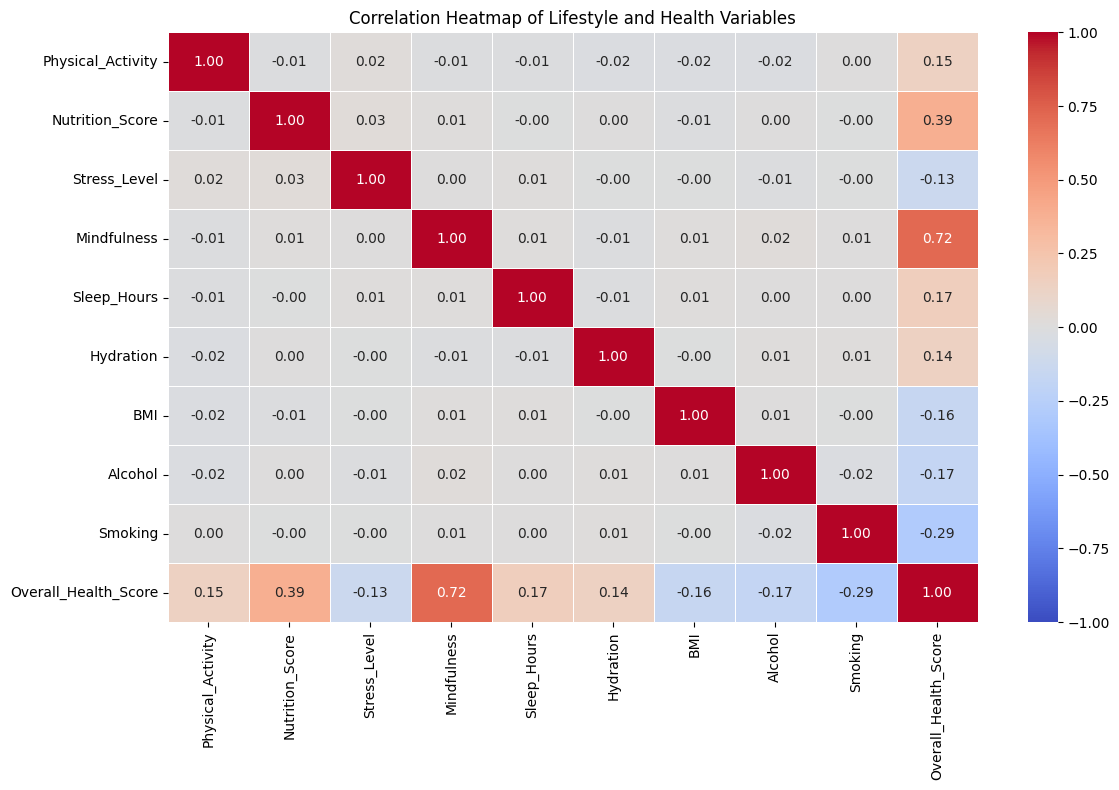

In [12]:

# Import libraries for the heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Create the heatmap with a colour scale centred on zero
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Lifestyle and Health Variables")

# Save and display the correlation heatmap
plt.tight_layout()

plt.savefig(
    visuals_folder / "02_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




**Explanation**

The correlation heatmap uses colours and numerical values to show the direction and strength of linear relationships between numerical variables. The correlation coefficients range from -1 to +1. Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Values close to zero indicate weak linear relationships.

The row and column for `Overall_Health_Score` are particularly important because they show how each lifestyle variable is associated with the calculated health score. The heatmap also allows us to examine relationships between the lifestyle variables themselves.

Because the overall health score is calculated using a predefined formula, the observed correlations may partly reflect the way the score was constructed. These associations do not establish causation or demonstrate the effects of real-world health interventions.


**Finding**

**Relationships with Overall_Health_Score**

* **Mindfulness (r = 0.72):** The strongest positive correlation with the calculated health score. Higher mindfulness values are associated with higher scores in this dataset.
* **Nutrition_Score (r = 0.39):** A moderate positive correlation with the calculated health score.
* **Smoking (r = -0.29):** The strongest negative correlation among the lifestyle variables. Higher smoking values are associated with lower calculated scores.
* **Other lifestyle variables:** Sleep_Hours (r = 0.17), Physical_Activity (r = 0.15) and Hydration (r = 0.14) show weak positive correlations. Alcohol (r = -0.17), BMI (r = -0.16) and Stress_Level (r = -0.13) show weak negative correlations.

**Relationships between lifestyle variables**

* Most correlations between the lifestyle variables are close to zero, indicating weak linear relationships between these pairs of variables in this dataset.
* This pattern may reflect how the synthetic dataset was generated. However, the heatmap alone cannot establish how the variables were generated or prove that they are independent.
* The generally weak correlations between lifestyle variables suggest limited linear relationships between them. A complete assessment of multicollinearity would require additional analysis.

**Limitations**

* Correlation does not establish causation.
* Pearson correlation measures linear relationships and may not fully capture non-linear patterns.
* The health score is formula-based and capped at 100, which may influence its observed relationships with lifestyle variables.
* The results describe this synthetic dataset and should not be used to make clinical recommendations or predict real-world health outcomes.


---

# Section 4: Comparing Lifestyle Measures Across Health Status Groups

This section compares lifestyle measures across the three `Health_Status` categories: Poor, Average and Good.

The analysis will help us explore how lifestyle measures differ between these groups within the dataset. Group sizes will also be examined so that the comparisons can be interpreted in context.

The dataset is synthetic, and `Health_Status` is derived from the calculated `Overall_Health_Score`. Therefore, differences between groups should be interpreted as patterns within the dataset, not as evidence of real-world health effects.

### 4.1 Count Records in Each Health Status Group

Before comparing lifestyle measures, we will count the number of records in each `Health_Status` category. This will help us understand the size of each group and identify any imbalance that could affect the interpretation of our comparisons.


In [13]:
# Count the number of records in each health status group
health_status_counts = df["Health_Status"].value_counts()

# Display the counts in a clear order
health_status_counts = health_status_counts.reindex(
    ["Poor", "Average", "Good"]
)

health_status_counts

Health_Status
Poor        418
Average    2823
Good       6759
Name: count, dtype: int64

**Explanation**

The output shows the number of records in each `Health_Status` category. There are 418 records classified as Poor, 2,823 as Average and 6,759 as Good.

These counts show that the groups are unevenly distributed. The Good group contains the largest number of records, while the Poor group contains the fewest. Knowing the group sizes is important when comparing lifestyle measures because differences should be interpreted in the context of how many records each group contains.


**Finding**

- **Good:** 6,759 records (67.59%), the largest group.
- **Average:** 2,823 records (28.23%).
- **Poor:** 418 records (4.18%), the smallest group.
- The groups are imbalanced, with most records classified as Good and relatively few classified as Poor.
- These categories are part of a synthetic dataset, and `Health_Status` is derived from the calculated `Overall_Health_Score`. The distribution describes this dataset and should not be interpreted as the distribution of health status in the real population.

### 4.2 Compare Average Lifestyle Measures Across Health Status Groups

This analysis compares the average values of the lifestyle variables across the Poor, Average and Good health-status groups.

The comparison will help identify which lifestyle measures have different average values across the three categories in this synthetic dataset. The results will be interpreted cautiously because `Health_Status` is derived from the calculated `Overall_Health_Score`.

Group averages describe patterns within this dataset and do not establish cause and effect or demonstrate real-world health outcomes.

In [14]:
# Calculate average lifestyle measures for each health status group
lifestyle_columns = [
    "Physical_Activity",
    "Nutrition_Score",
    "Stress_Level",
    "Mindfulness",
    "Sleep_Hours",
    "Hydration",
    "BMI",
    "Alcohol",
    "Smoking"
]

# Group records by health status and calculate the averages
group_averages = df.groupby("Health_Status")[lifestyle_columns].mean()

# Display the results in Poor, Average, Good order
group_averages.reindex(["Poor", "Average", "Good"]).round(2)

,Physical_Activity,Nutrition_Score,Stress_Level,Mindfulness,Sleep_Hours,Hydration,BMI,Alcohol,Smoking
Health_Status,,,,,,,,,
Poor,37.83,4.99,5.46,3.29,6.33,2.27,25.26,5.28,10.44
Average,42.03,6.30,5.25,7.87,6.77,2.39,24.65,4.01,6.92
Good,46.75,7.37,4.85,19.03,7.14,2.56,23.79,3.21,4.91


**Explanation**

The table compares the average values of nine lifestyle measures across the Poor, Average and Good health-status groups. Each value represents the mean for that variable within the relevant group.

Comparing these averages helps identify patterns across the three categories. For example, we can examine whether average physical activity, nutrition scores, mindfulness and sleep hours are higher or lower in different groups.

The results describe differences within this synthetic dataset. Since `Health_Status` is derived from the formula-based `Overall_Health_Score`, these differences do not establish that any lifestyle measure causes better or poorer health.


**Finding**

The group averages show the following patterns within the synthetic dataset:

* **Physical activity:** The average increases from 37.83 in the Poor group to 42.03 in the Average group and 46.75 in the Good group.
* **Nutrition score:** The average increases from 4.99 (Poor) to 6.30 (Average) and 7.37 (Good).
* **Mindfulness:** The average increases from 3.29 minutes per day (Poor) to 7.87 (Average) and 19.03 (Good). Differences between variables should not be ranked   directly because they use different units and scales.
* **Sleep hours:** The average increases from 6.33 hours (Poor) to 6.77 (Average) and 7.14 (Good).
* **Stress level:** The average decreases from 5.46 (Poor) to 5.25 (Average) and 4.85 (Good).
* **Hydration:** The average increases from 2.27 litres per day (Poor) to 2.39 (Average) and 2.56 (Good).
* **BMI:** The average decreases from 25.26 (Poor) to 24.65 (Average) and 23.79 (Good).
* **Alcohol:** The average decreases from 5.28 units per week (Poor) to 4.01 (Average) and 3.21 (Good).
* **Smoking:** The average decreases from 10.44 cigarettes per day (Poor) to 6.92 (Average) and 4.91 (Good).

**Interpretation and limitations**

* The Good group has higher average physical activity, nutrition scores, mindfulness, sleep duration and hydration than the Poor group.
* The Good group also has lower average stress, BMI, alcohol consumption and smoking values than the Poor group.
* These are descriptive differences within the synthetic dataset. They do not establish cause and effect.
* Because `Health_Status` is derived from a formula-based score, these patterns may partly reflect the rules used to calculate that score. They should not be interpreted as evidence of real-world health effects.



### 4.3 Visualise Lifestyle Differences Across Health Status Groups

Visualisations help communicate differences in average lifestyle measures across the Poor, Average and Good health-status groups.

This section uses bar charts to compare selected lifestyle measures across the three groups. The charts will help make the observed patterns easier to interpret and communicate.

The comparisons describe the synthetic dataset and should not be interpreted as evidence of cause and effect or real-world health outcomes.

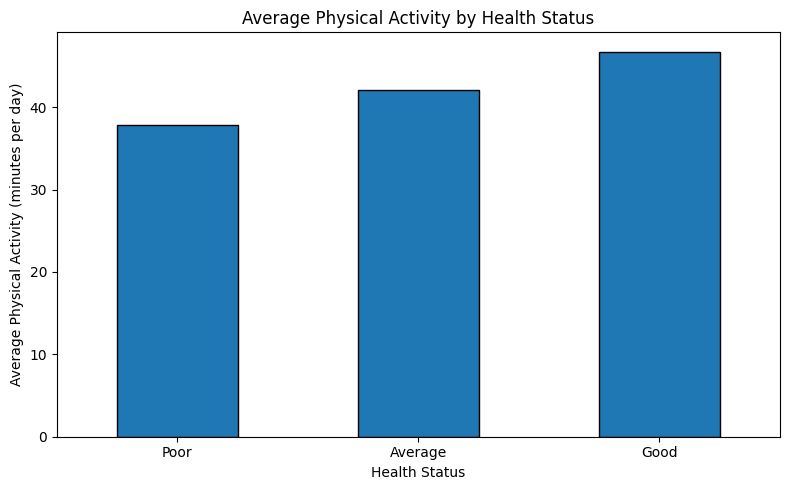

<Figure size 640x480 with 0 Axes>

In [15]:
# Calculate average physical activity for each health status group
physical_activity_averages = (
    df.groupby("Health_Status")["Physical_Activity"]
    .mean()
    .reindex(["Poor", "Average", "Good"])
)

# Create a bar chart
plt.figure(figsize=(8, 5))
physical_activity_averages.plot(kind="bar", edgecolor="black")

# Add a title and axis labels
plt.title("Average Physical Activity by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Average Physical Activity (minutes per day)")

# Display the chart
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
# Save and display the physical activity chart
plt.tight_layout()

plt.savefig(
    visuals_folder / "03_physical_activity_by_health_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




**Explanation**

The bar chart compares average daily physical activity across the Poor, Average and Good health-status groups. The horizontal axis shows the health-status categories, while the vertical axis shows average physical activity in minutes per day.

The chart shows an increasing pattern across the groups. The Poor group has the lowest average physical activity at 37.83 minutes per day, followed by the Average group at 42.03 minutes and the Good group at 46.75 minutes.

These values describe differences within the synthetic dataset. They do not establish that higher physical activity causes a better health-status classification.


**Finding**

* Average physical activity increases across the groups: **37.83 minutes/day** in Poor, **42.03 minutes/day** in Average and **46.75 minutes/day** in Good.
* The Good group has the highest average physical activity, while the Poor group has the lowest.
* These are differences within the synthetic dataset; they do not prove that physical activity causes a better health-status classification.


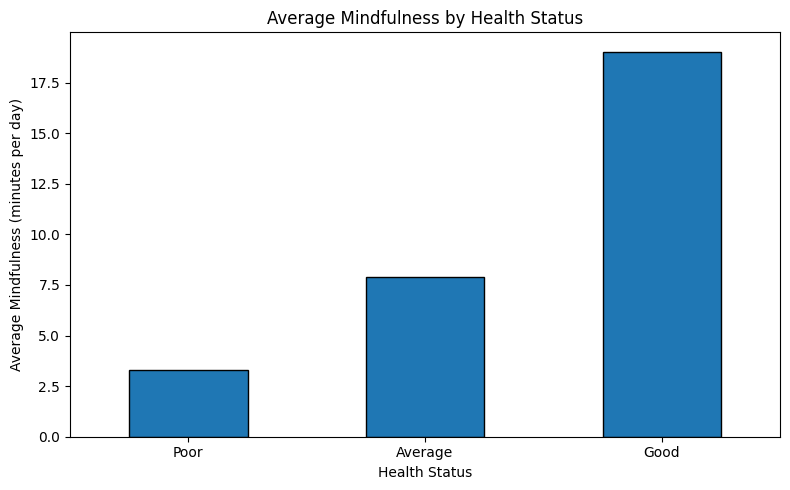

<Figure size 640x480 with 0 Axes>

In [16]:
# Calculate average mindfulness for each health status group
mindfulness_averages = (
    df.groupby("Health_Status")["Mindfulness"]
    .mean()
    .reindex(["Poor", "Average", "Good"])
)

# Create a bar chart
plt.figure(figsize=(8, 5))
mindfulness_averages.plot(kind="bar", edgecolor="black")

# Add a title and axis labels
plt.title("Average Mindfulness by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Average Mindfulness (minutes per day)")

# Display the chart
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

# Save and display the mindfulness chart
plt.tight_layout()

plt.savefig(
    visuals_folder / "04_mindfulness_by_health_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




**Explanation**

The bar chart compares average daily mindfulness across the Poor, Average and Good health-status groups. The horizontal axis shows the health-status categories, while the vertical axis shows average mindfulness in minutes per day.

The Poor group has the lowest average at 3.29 minutes per day, followed by the Average group at 7.87 minutes. The Good group has the highest average at 19.03 minutes per day.

These results describe patterns within the synthetic dataset. They do not establish that mindfulness causes a better health-status classification.


**Finding**

* Average mindfulness increases across the groups: **3.29 minutes/day** in Poor, **7.87 minutes/day** in Average and **19.03 minutes/day** in Good.
* The Good group has the highest average mindfulness, with a larger difference between groups than we observed for physical activity.
* These are patterns within the synthetic dataset. They do not prove that mindfulness causes a better health-status classification.


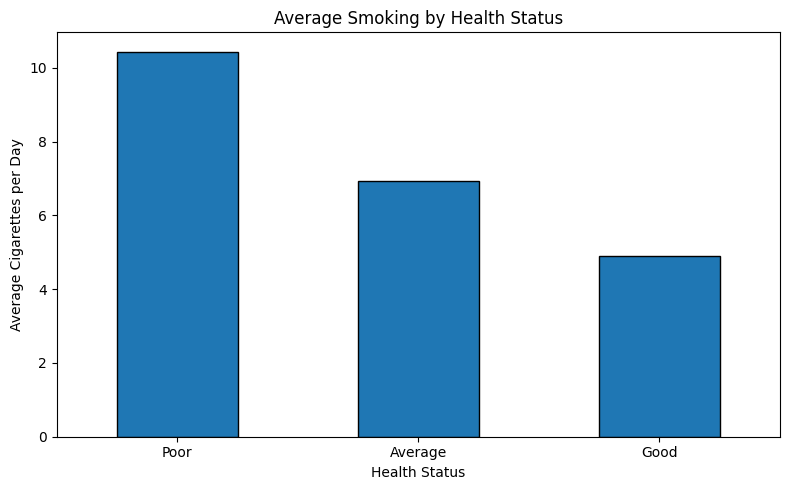

<Figure size 640x480 with 0 Axes>

In [17]:
# Calculate average smoking levels for each health status group
smoking_averages = (
    df.groupby("Health_Status")["Smoking"]
    .mean()
    .reindex(["Poor", "Average", "Good"])
)

# Create a bar chart
plt.figure(figsize=(8, 5))
smoking_averages.plot(kind="bar", edgecolor="black")

# Add a title and axis labels
plt.title("Average Smoking by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Average Cigarettes per Day")

# Display the chart
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Save and display the smoking chart
plt.tight_layout()

plt.savefig(
    visuals_folder / "05_smoking_by_health_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Explanation**

The bar chart compares average daily smoking levels across the Poor, Average and Good health-status groups. The horizontal axis shows the health-status categories, while the vertical axis shows the average number of cigarettes per day.

The Poor group has the highest average at 10.44 cigarettes per day, followed by the Average group at 6.92. The Good group has the lowest average at 4.91 cigarettes per day.

These results describe patterns within the synthetic dataset. They do not establish that smoking levels cause a particular health-status classification.




**Finding**

* Average smoking levels decrease across the groups: **10.44 cigarettes/day** in Poor, **6.92 cigarettes/day** in Average and **4.91 cigarettes/day** in Good.
* The Poor group has the highest average smoking level, while the Good group has the lowest.
* These patterns describe the synthetic dataset and do not prove that smoking levels cause a particular health-status classification.


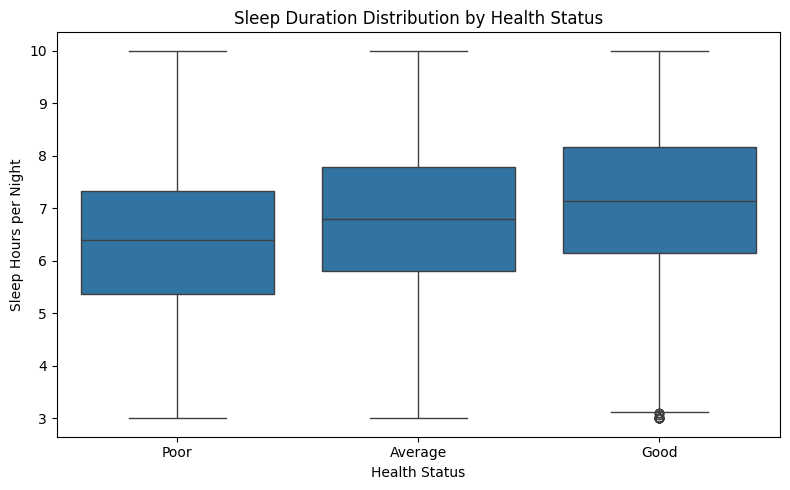

<Figure size 640x480 with 0 Axes>

In [18]:
# Create a box plot to compare sleep duration across health status groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Health_Status",
    y="Sleep_Hours",
    order=["Poor", "Average", "Good"]
)

# Add a title and axis labels
plt.title("Sleep Duration Distribution by Health Status")
plt.xlabel("Health Status")
plt.ylabel("Sleep Hours per Night")

# Display the chart
plt.tight_layout()
plt.show()

# Save and display the sleep-hours box plot
plt.tight_layout()

plt.savefig(
    visuals_folder / "06_sleep_hours_by_health_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



**Explanation**

The box plot compares the distribution of sleep duration across the Poor, Average and Good health-status groups. The line inside each box represents the median, while the box shows the middle 50% of sleep values. Points beyond the whiskers indicate potential outliers.

The median sleep duration increases from 6.39 hours in the Poor group to 6.79 hours in the Average group and 7.14 hours in the Good group. The middle 50% of sleep values also shifts towards higher durations across these groups.

The distributions overlap, although the Good group has a higher median sleep duration. These differences describe patterns in the synthetic dataset and do not demonstrate that sleep duration causes a particular health-status classification.


**Finding**

* **Median sleep duration increases** across the groups: 6.39 hours for Poor, 6.79 hours for Average and 7.14 hours for Good.
* The Good group has the highest median sleep duration, while the Poor group has the lowest.
* The middle 50% of sleep values shifts towards longer sleep durations across the groups, although the distributions overlap.
* These findings describe the synthetic dataset and do not establish a causal relationship between sleep duration and health status.


### 4.4 Explore the Relationship Between Mindfulness and Overall Health Score

This analysis uses an interactive scatter plot to explore the relationship between mindfulness minutes per day and the overall health score.

Each point represents one record in the dataset. The interactive chart allows the values to be explored more closely and colours the points according to health status.

The overall health score is calculated using lifestyle measures, including mindfulness. Therefore, any observed relationship is partly influenced by the scoring formula and should not be interpreted as evidence that mindfulness causes better health. The dataset is synthetic and does not represent real-world clinical outcomes.


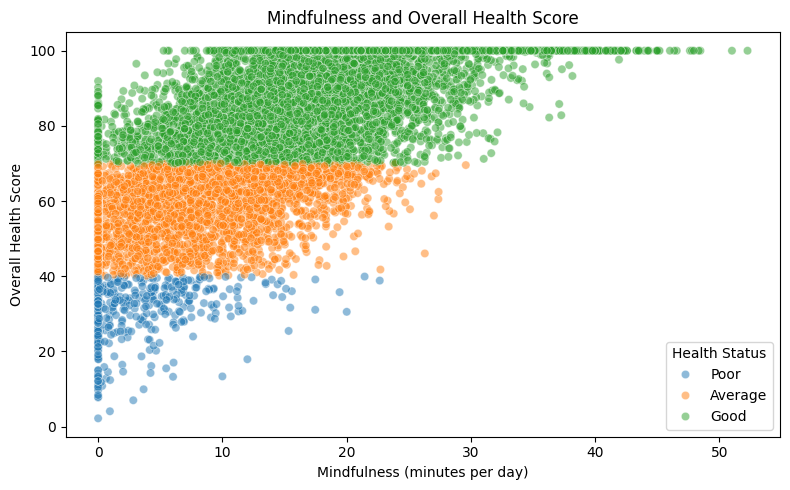

<Figure size 640x480 with 0 Axes>

In [19]:
# Create a scatter plot to explore mindfulness and overall health score
plt.figure(figsize=(8, 5))

# Plot each record as a point
sns.scatterplot(
    data=df,
    x="Mindfulness",
    y="Overall_Health_Score",
    hue="Health_Status",
    alpha=0.5
)

# Add a title and axis labels
plt.title("Mindfulness and Overall Health Score")
plt.xlabel("Mindfulness (minutes per day)")
plt.ylabel("Overall Health Score")

# Display the legend and chart
plt.legend(title="Health Status")
plt.tight_layout()
plt.show()

# Save and display the mindfulness scatter plot
plt.tight_layout()

plt.savefig(
    visuals_folder / "07_mindfulness_vs_overall_health_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




**Explanation**

The scatter plot explores the relationship between mindfulness minutes per day and the Overall Health Score. Each point represents one record, and the colours distinguish the Poor, Average and Good health-status groups.

The chart shows that records with higher mindfulness values tend to appear at higher overall health scores. The points are spread across the chart, showing variation between individual records.

However, the Overall Health Score is calculated partly using mindfulness. Therefore, the observed pattern is partly influenced by the scoring formula and does not establish that mindfulness causes a higher health score. The dataset is synthetic, so these results should not be treated as evidence of real-world health outcomes.


**Finding**

* The scatter plot shows a general positive relationship between mindfulness minutes and the Overall Health Score in this synthetic dataset.
* The points are distributed across the three health-status groups, allowing their patterns to be compared visually.
* Because mindfulness contributes to the calculated score, this relationship is not independent evidence of a health benefit and does not establish cause and effect.


### 4.5 Summary of Lifestyle Comparisons

This section compared lifestyle measures across the Poor, Average and Good health-status groups using descriptive statistics and visualisations.

The analysis identified several patterns within the synthetic dataset:

* The Good group had higher average physical activity, nutrition scores, mindfulness minutes, sleep duration and hydration than the Poor group.
* The Good group had lower average stress levels, BMI, alcohol consumption and smoking levels than the Poor group.
* The box plot showed a higher median sleep duration in the Good group than in the Poor group.
* The scatter plot showed a general positive relationship between mindfulness minutes and the Overall Health Score.

The group comparisons provide a descriptive overview of differences within the dataset. However, the health-status categories are derived from the calculated Overall Health Score, which itself uses lifestyle measures. Therefore, the observed patterns should not be interpreted as independent evidence that these lifestyle measures cause better health.

The dataset is synthetic, and its results cannot be generalised to real people or used to make clinical conclusions.


# Section 5: Overall Conclusions, Limitations and Ethical Considerations

This section brings together the main findings from the exploratory data analysis and considers their meaning, limitations and ethical implications.

It summarises the key patterns identified in the dataset, explains factors that may affect the interpretation of the results, and discusses the importance of responsible data analysis and communication.

As the dataset is synthetic and the overall health score is calculated from lifestyle measures, the findings must be interpreted carefully. They should not be treated as clinical evidence or generalised to the real population.


### 5.1 Overall Conclusions

The exploratory data analysis identified several patterns in the synthetic lifestyle and health dataset.

The correlation analysis showed that mindfulness had the strongest positive correlation with the Overall_Health_Score, followed by Nutrition_Score. Smoking had the strongest negative correlation with the score among the lifestyle measures examined.

The comparison of health-status groups showed that the Good group generally had higher average physical activity, nutrition scores, mindfulness minutes and sleep duration than the Poor group. The Good group also had lower average smoking levels, alcohol consumption, stress levels and BMI.

The analysis also showed that the health-status groups were unevenly distributed, with the Good group containing most records and the Poor group containing considerably fewer.

Overall, the analysis demonstrates how descriptive statistics, correlation analysis and visualisations can help identify patterns in a dataset.


### 5.2 Limitations of the Analysis

Several limitations should be considered when interpreting the results of this analysis.

* **Synthetic dataset:** The data is synthetic and does not represent actual individuals or the real-world population. The findings cannot be generalised to real-world health outcomes.
* **Formula-derived health score:** The Overall_Health_Score is calculated from the lifestyle variables included in the dataset. Consequently, correlations between these variables and the score are partly influenced by the scoring formula.
* **Derived health-status categories:** Health_Status is based on the Overall_Health_Score. Differences between the Poor, Average and Good groups are therefore linked to how the score and categories were constructed.
* **No evidence of causation:** Correlations and differences between groups show associations within the dataset. They do not prove that a particular lifestyle behaviour causes a change in health.
* **Uneven group sizes:** The Good group contains substantially more records than the Poor group. This imbalance should be considered when comparing the groups.
* **Score ceiling:** The Overall_Health_Score is capped at 100. This creates a ceiling effect, meaning differences between records with scores near the maximum may be less visible.

These limitations mean that the analysis is useful for practising exploratory data analysis and identifying patterns in synthetic data, but it should not be used to make clinical decisions or draw conclusions about real people's health.


### 5.3 Ethical Considerations and Responsible Interpretation

Ethical considerations are important when analysing and communicating health-related data, even when the dataset is synthetic.

* **Privacy and confidentiality:** The dataset is synthetic and does not represent actual individuals. This reduces the privacy risks associated with analysing personal health information. However, real-world health data would require appropriate privacy protections and secure handling.
* **Responsible interpretation:** The results should be presented as patterns within the synthetic dataset, not as evidence of actual health outcomes or medical advice.
* **Avoiding misleading conclusions:** Correlation does not establish causation. The analysis should not suggest that a particular lifestyle behaviour directly causes better or poorer health.
* **Fair representation:** The health-status groups have different numbers of records. These differences should be acknowledged to avoid misleading comparisons.
* **Transparent communication:** Charts should have clear titles, labelled axes and understandable categories. Findings and limitations should be explained so readers can interpret the results appropriately.
* **Awareness of score design:** The Overall_Health_Score and Health_Status are calculated from the dataset's variables. Their construction should be disclosed so readers understand how this influences the results.

Overall, responsible reporting requires transparency about the synthetic data, the scoring method and the limitations of the analysis. These practices help prevent the findings from being misinterpreted or used to make unsupported claims about real people's health.


### 5.4 Recommendations for Future Analysis

Future analysis could build on this project in several ways:

* **Use appropriate real-world data:** Where suitable, ethically sourced and properly governed health data could be used to investigate whether similar patterns appear in real populations.
* **Validate the scoring method:** The scoring formula could be reviewed with relevant health professionals to assess whether its design and weighting are appropriate for its intended purpose.
* **Investigate alternative approaches:** Different analytical methods or scoring approaches could be explored to understand how methodological choices influence the results.
* **Improve data documentation:** Clearer definitions of variables, measurement units and scoring rules would help users understand and interpret the dataset.
* **Strengthen validation:** Future work could assess how well the scoring method represents the health-related concepts it is intended to describe, rather than assuming the calculated score is a validated health measure.

These recommendations could help make future analyses more informative and transparent. Any work involving real health data would require appropriate ethical consideration, privacy protection and data governance.
